In [34]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

In [35]:
sns.set_theme(style="ticks", context="talk")

data_dir = "/data_vol/analysis_outputs/QTL_analysis/qtl_properties_mostafavi"
data_dir = "/data/processed/QTL_analysis/qtl_properties_mostafavi"

results_dirs_dict = {"GWAS": {"results_dir": f"{data_dir}/gwas",
                              "results_prefix": "gwas"},
                     "eQTL": {"results_dir": f"{data_dir}/rna",
                              "results_prefix": "qtl"},
                     "caQTL": {"results_dir": f"{data_dir}/atac",
                              "results_prefix": "qtl"}}
levels = ["Cohort", "L1_manual", "L2_manual"]

In [36]:
basic_results = []
for phenotype, phenotype_results_dict in results_dirs_dict.items():
    if phenotype == "GWAS":
        results_dir = phenotype_results_dict["results_dir"]
        results_prefix = phenotype_results_dict["results_prefix"]
        tmp_df = pd.read_csv(f"{results_dir}/out/{results_prefix}.basic_props.CI.props")
        tmp_df["Phenotype"] = phenotype
        basic_results.append(tmp_df)
    else:
        for level in levels:
            results_dir = phenotype_results_dict["results_dir"]
            results_prefix = phenotype_results_dict["results_prefix"]
            try:
                tmp_df = pd.read_csv(f"{results_dir}/{level}/out/{results_prefix}.basic_props.CI.props")
                tmp_df["Phenotype"] = phenotype
                tmp_df["Level"] = level
                basic_results.append(tmp_df)
            except:
                continue
    
basic_results = pd.concat(basic_results)

In [37]:
tss_results = []
for phenotype, phenotype_results_dict in results_dirs_dict.items():
    if phenotype == "GWAS":
        results_dir = phenotype_results_dict["results_dir"]
        results_prefix = phenotype_results_dict["results_prefix"]
        tmp_df = pd.read_csv(f"{results_dir}/out/{results_prefix}.TSS_props.CI")
        tmp_df["Phenotype"] = phenotype
        tss_results.append(tmp_df)
    else:
        for level in levels:
            results_dir = phenotype_results_dict["results_dir"]
            results_prefix = phenotype_results_dict["results_prefix"]
            try:
                tmp_df = pd.read_csv(f"{results_dir}/{level}/out/{results_prefix}.TSS_props.CI")
                tmp_df["Phenotype"] = phenotype
                tmp_df["Level"] = level
                tss_results.append(tmp_df)
            except:
                continue
tss_results = pd.concat(tss_results)
tss_results = tss_results[tss_results["dTSS_bin"].abs() < 100]

In [38]:
cre_results = []
for phenotype, phenotype_results_dict in results_dirs_dict.items():
    if phenotype == "GWAS":
        results_dir = phenotype_results_dict["results_dir"]
        results_prefix = phenotype_results_dict["results_prefix"]
        tmp_df = pd.read_csv(f"{results_dir}/out/{results_prefix}.promoter_enhancer.enrichments.CI")
        tmp_df["Phenotype"] = phenotype
        cre_results.append(tmp_df)
    else:
        for level in levels:
            results_dir = phenotype_results_dict["results_dir"]
            results_prefix = phenotype_results_dict["results_prefix"]
            try:
                tmp_df = pd.read_csv(f"{results_dir}/{level}/out/{results_prefix}.promoter_enhancer.enrichments.CI")
                tmp_df["Phenotype"] = phenotype
                tmp_df["Level"] = level
                cre_results.append(tmp_df)
            except:
                continue
    
cre_results = pd.concat(cre_results)

In [39]:
colors = {"GWAS": "#8c510a",
          "eQTL": {"Cohort": "#a50f15", "L1_manual": "#de2d26", "L2_manual": "#fb6a4a"},
          "caQTL": {"Cohort": "#08519c", "L1_manual": "#3182bd", "L2_manual": "#6baed6"}}

## PLI plots

/tmp/ipykernel_1823/3416812453.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["x"] = [0, 0.05, # GWAS
/tmp/ipykernel_1823/3416812453.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["color"] = [colors["GWAS"], colors["GWAS"],
/tmp/ipykernel_1823/3416812453.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-doc

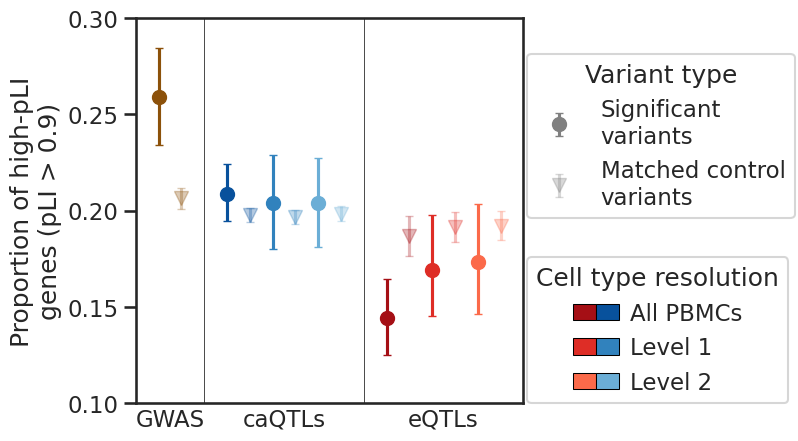

In [46]:
###new ordering###

plot_df = basic_results[basic_results["annot"] == "prop_HI"]

# 1. Update X-coordinates: 
# GWAS (0-0.05), caQTL (0.15-0.4), eQTL (0.5-0.75)
plot_df["x"] = [0, 0.05, # GWAS
                0.5, 0.55, 0.6, 0.65, 0.7, 0.75, # eQTL (Moved to end)
                0.15, 0.2, 0.25, 0.3, 0.35, 0.4] # caQTL (Moved to middle)

# 2. Update Color mapping to match the new order
plot_df["color"] = [colors["GWAS"], colors["GWAS"], 
                    colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"]]

plot_df["marker"] = "o"
plot_df["alpha"] = 1
plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

fig, ax = plt.subplots(figsize=(5, 5))
for i, row in plot_df.iterrows():
    plt.errorbar(row["x"], row["mean"], 
                 yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], alpha=row["alpha"], color=row["color"],
                 markersize=10, capsize=3, linestyle="none")

# 3. Adjust vertical lines to separate the new sections
plt.vlines(0.1, 0.1, 0.3, color="black", linewidth=0.5) # After GWAS
plt.vlines(0.45, 0.1, 0.3, color="black", linewidth=0.5) # After caQTL

plt.ylim(0.1, 0.3)
plt.xlim(-0.05, 0.8)

plt.yticks(np.arange(0.1, 0.31, 0.05))

# 4. Update Tick Labels and positions
# GWAS center ~0.025, caQTL center ~0.275, eQTL center ~0.625
plt.xticks([0.025, 0.275, 0.625], ["GWAS", "caQTLs", "eQTLs"])
ax.tick_params(axis='x', which='both', length=0)

plt.ylabel("Proportion of high-pLI\ngenes (pLI > 0.9)")
plt.xlabel("")

# Updated second legend to match GWAS -> caQTL -> eQTL order
# We define eQTL (1) and caQTL (2) patches
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched control\nvariants")
first_legend = ax.legend(handles=[l1, l2], loc=(1.01, 0.48), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax.add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/prop_high_pLI.pdf", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/prop_high_pLI.png", dpi=300, bbox_inches="tight")

/tmp/ipykernel_1823/3422612543.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["x"] = [0, 0.05, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75]
/tmp/ipykernel_1823/3422612543.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["color"] = [colors["GWAS"], colors["GWAS"],
/tmp/ipykernel_1823/3422612543.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats i

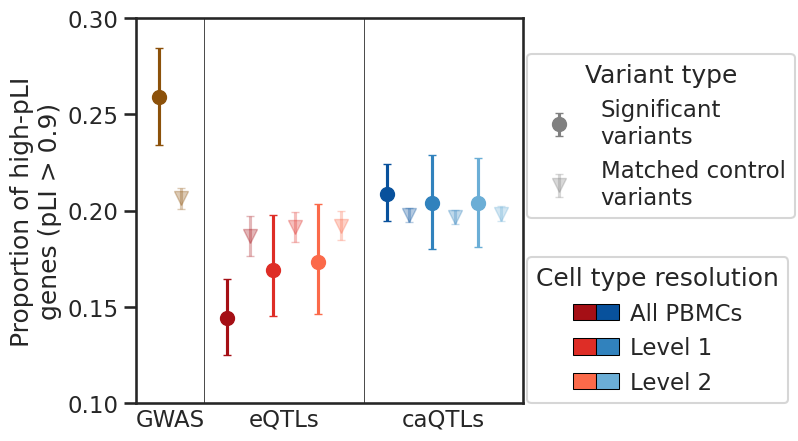

In [47]:
###original ordering###

plot_df = basic_results[basic_results["annot"] == "prop_HI"]
plot_df["x"] = [0, 0.05, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75]
plot_df["color"] = [colors["GWAS"], colors["GWAS"], 
                    colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"]]
plot_df["marker"] = "o"
plot_df["alpha"] = 1
plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

fig, ax = plt.subplots(figsize=(5, 5))
for i, row in plot_df.iterrows():
    plt.errorbar(row["x"], row["mean"], 
                 yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], alpha=row["alpha"], color=row["color"],
                 markersize=10, capsize=3, linestyle="none")
    
plt.vlines(0.1, 0.1, 0.3, color="black", linewidth=0.5)
plt.vlines(0.45, 0.1, 0.3, color="black", linewidth=0.5)
plt.ylim(0.1, 0.3)
plt.xlim(-0.05, 0.8)

plt.yticks(np.arange(0.1, 0.31, 0.05))
plt.xticks([0.025, 0.275, 0.625], ["GWAS", "eQTLs", "caQTLs"])
ax.tick_params(axis='x', which='both',length=0)

plt.ylabel("Proportion of high-pLI\ngenes (pLI > 0.9)")
plt.xlabel("")

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched control\nvariants")
first_legend = ax.legend(handles=[l1, l2], loc=(1.01, 0.48), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax.add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/prop_high_pLI.pdf", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/prop_high_pLI.png", dpi=300, bbox_inches="tight")

/tmp/ipykernel_1823/260257873.py:24: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3


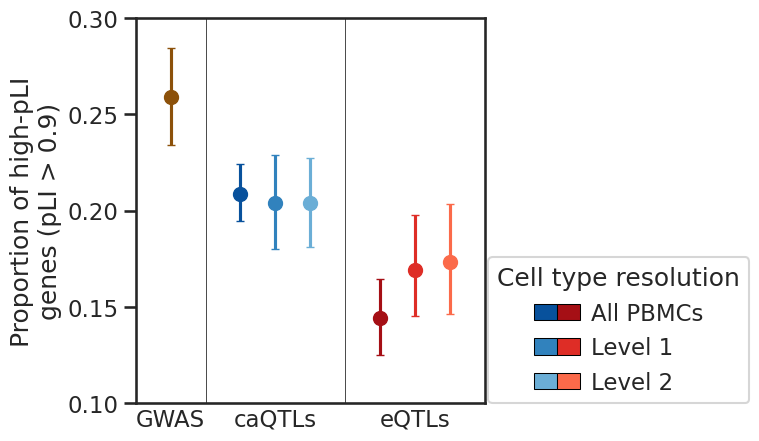

In [51]:
###new ordering###
###updated ordering: GWAS -> caQTL -> eQTL###
plot_df = basic_results[basic_results["annot"] == "prop_HI"]
# remove matched variants
plot_df = plot_df.loc[~plot_df["cat"].str.contains("matched")]

# Reorder the dataframe rows to match the desired plot order: GWAS, then caQTL rows, then eQTL rows
# Assuming the original order in basic_results was GWAS, eQTL (3 rows), caQTL (3 rows)
plot_df = pd.concat([
    plot_df.iloc[[0]],           # GWAS
    plot_df.iloc[4:7],           # caQTLs
    plot_df.iloc[1:4]            # eQTLs
]).reset_index(drop=True)

plot_df["x"] = [0, 0.1, 0.15, 0.2, 0.3, 0.35, 0.4]
plot_df["color"] = [
    colors["GWAS"], 
    colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"],
    colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"]
]
plot_df["marker"] = "o"
plot_df["alpha"] = 1
plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

fig, ax = plt.subplots(figsize=(4.5, 5))
for i, row in plot_df.iterrows():
    plt.errorbar(row["x"], row["mean"], 
                 yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], alpha=row["alpha"], color=row["color"],
                 markersize=10, capsize=3, linestyle="none")
    
plt.vlines(0.05, 0.1, 0.3, color="black", linewidth=0.5)
plt.vlines(0.25, 0.1, 0.3, color="black", linewidth=0.5)
plt.ylim(0.1, 0.3)
plt.xlim(-0.05, 0.45)

plt.yticks(np.arange(0.1, 0.31, 0.05))
# Swapped the tick labels for the last two groups
plt.xticks([0, 0.15, 0.35], ["GWAS", "caQTLs", "eQTLs"])
ax.tick_params(axis='x', which='both', length=0)

plt.ylabel("Proportion of high-pLI\ngenes (pLI > 0.9)")
plt.xlabel("")

# Update legend handles to match the new visual order (caQTL first, then eQTL)
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)

# Swapping the handle order in the legend: [caQTL patches, eQTL patches]
plt.legend(handles=[pa2, pb2, pc2, pa1, pb1, pc1],
           labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
           ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
           loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/prop_high_pLI_no_matched_swapped.pdf", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/prop_high_pLI_no_matched_swapped.png", dpi=300, bbox_inches="tight")

/tmp/ipykernel_11588/4100587231.py:13: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3


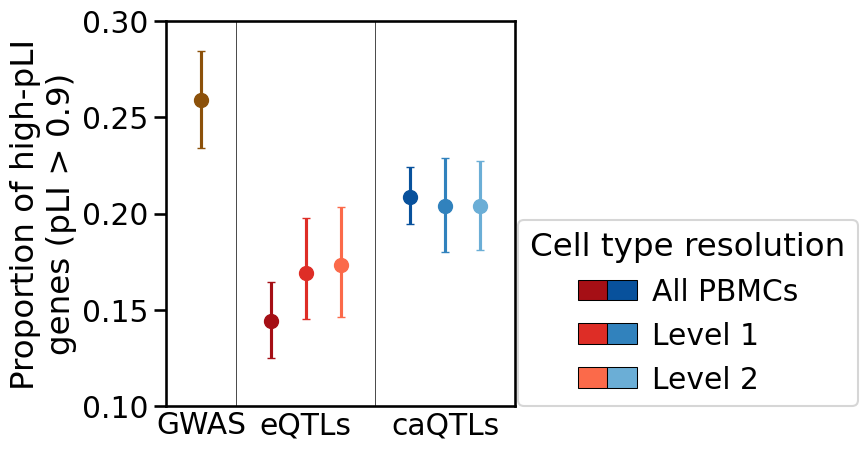

In [ ]:
###original ordering###
plot_df = basic_results[basic_results["annot"] == "prop_HI"]
# remove matched variants
plot_df = plot_df.loc[~plot_df["cat"].str.contains("matched")]
plot_df["x"] = [0, 0.1, 0.15, 0.2, 0.3, 0.35, 0.4]
plot_df["color"] = [colors["GWAS"], 
                    colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"]]
plot_df["marker"] = "o"
plot_df["alpha"] = 1
plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

fig, ax = plt.subplots(figsize=(4.5, 5))
for i, row in plot_df.iterrows():
    plt.errorbar(row["x"], row["mean"], 
                 yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], alpha=row["alpha"], color=row["color"],
                 markersize=10, capsize=3, linestyle="none")
    
plt.vlines(0.05, 0.1, 0.3, color="black", linewidth=0.5)
plt.vlines(0.25, 0.1, 0.3, color="black", linewidth=0.5)
plt.ylim(0.1, 0.3)
plt.xlim(-0.05, 0.45)

plt.yticks(np.arange(0.1, 0.31, 0.05))
plt.xticks([0, 0.15, 0.35], ["GWAS", "eQTLs", "caQTLs"])
ax.tick_params(axis='x', which='both',length=0)

plt.ylabel("Proportion of high-pLI\ngenes (pLI > 0.9)")
plt.xlabel("")

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/prop_high_pLI_no_matched.pdf", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/prop_high_pLI_no_matched.png", dpi=300, bbox_inches="tight")

## TSS plots

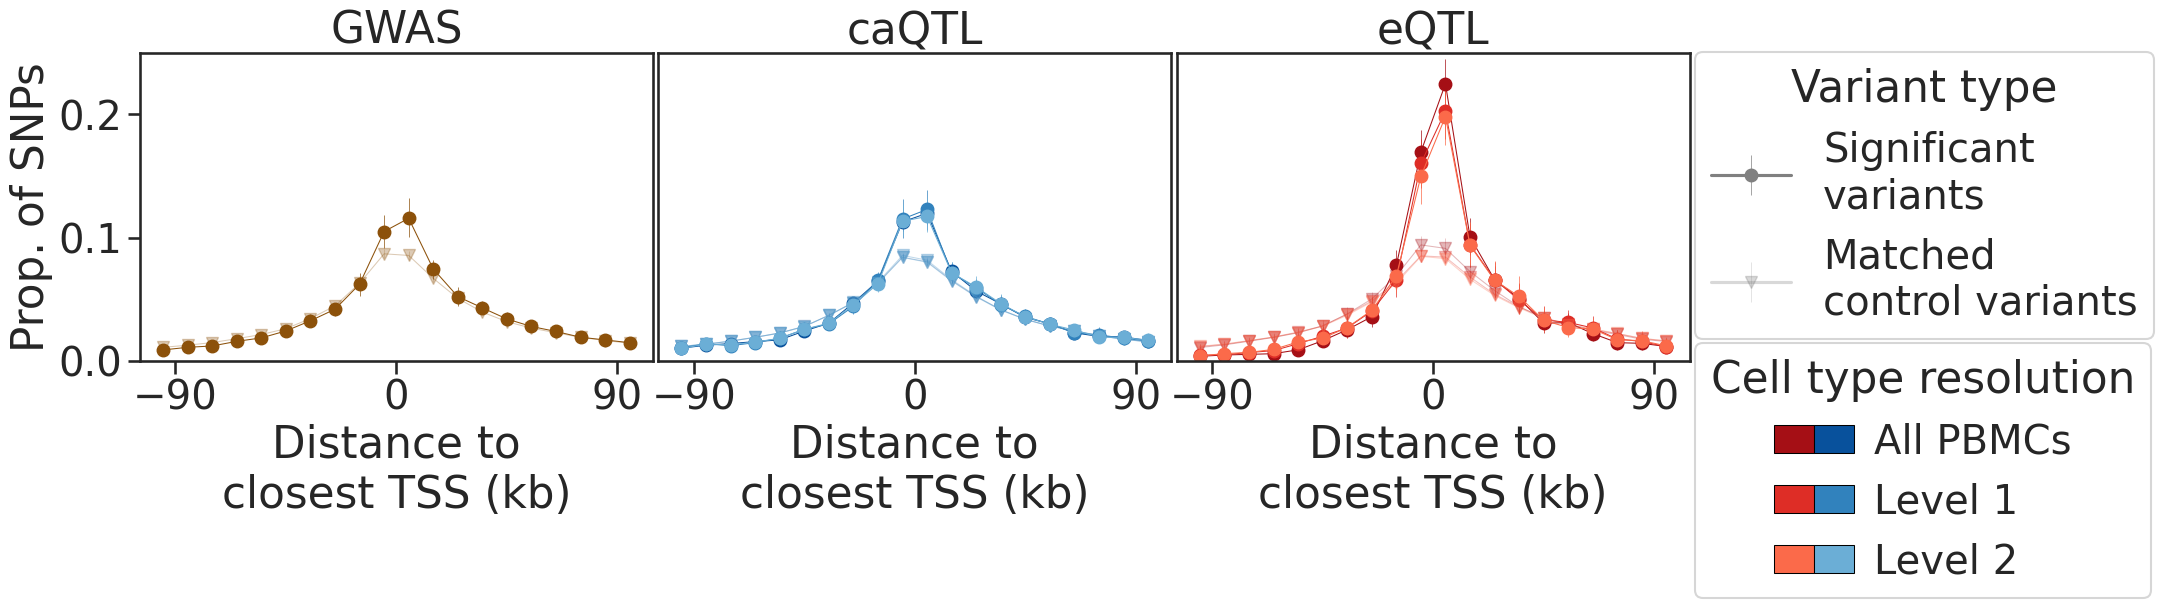

In [54]:
## REORDERED ##
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch

sns.set_context('talk', font_scale=1.75)

fig, ax = plt.subplots(1, 3, figsize=(20, 4))
plt.subplots_adjust(wspace=0.01) 

# --- Panel 0: GWAS (Stays the same) ---
plot_df = tss_results[tss_results["cat"] == "GWAS"]
ax[0].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, 
               marker="o", color=colors["GWAS"], label="GWAS")

plot_df = tss_results[tss_results["cat"] == "GWAS_matched"]
ax[0].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, marker="v", color=colors["GWAS"], alpha=0.3, label="GWAS matched")

ax[0].set_ylim(0, 0.25)
ax[0].set_xticks([-90, 0, 90])
ax[0].set_ylabel("Prop. of SNPs")
ax[0].set_xlabel("Distance to\nclosest TSS (kb)")
ax[0].set_title("GWAS")


# --- Panels 1 & 2: caQTL then eQTL ---
# Swapping the order in the list below handles the panel assignment
for i, modality in enumerate(["caQTL", "eQTL"]):
    for j, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
        # plot significant variants
        plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                              (tss_results["Level"] == level) &
                              (tss_results["cat"] == "eQTL")]
        
        ax[i+1].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, 
               marker="o", color=colors[modality][level], label=level)
        
        # plot matched variants
        plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                              (tss_results["Level"] == level) &
                              (tss_results["cat"] == "eQTL_matched")]
        
        ax[i+1].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, marker="v", color=colors[modality][level], alpha=0.3)
        
        # plot labels
        ax[i+1].set_ylim(0, 0.25)
        ax[i+1].set_yticks([])
        ax[i+1].set_xticks([-90, 0, 90])
        ax[i+1].set_xlabel("Distance to\nclosest TSS (kb)")
        ax[i+1].set_title(modality)

# --- Legends (Attached to the last panel, ax[2]) ---
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
                  elinewidth=0.5, label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
                  elinewidth=0.5, label="Matched\ncontrol variants")

first_legend = ax[2].legend(handles=[l1, l2], loc=(1.01, 0.07), title='Variant type')
ax[2].add_artist(first_legend)

# Color patches for legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)

plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.77), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/TSS_distance.png", dpi=300, bbox_inches="tight")

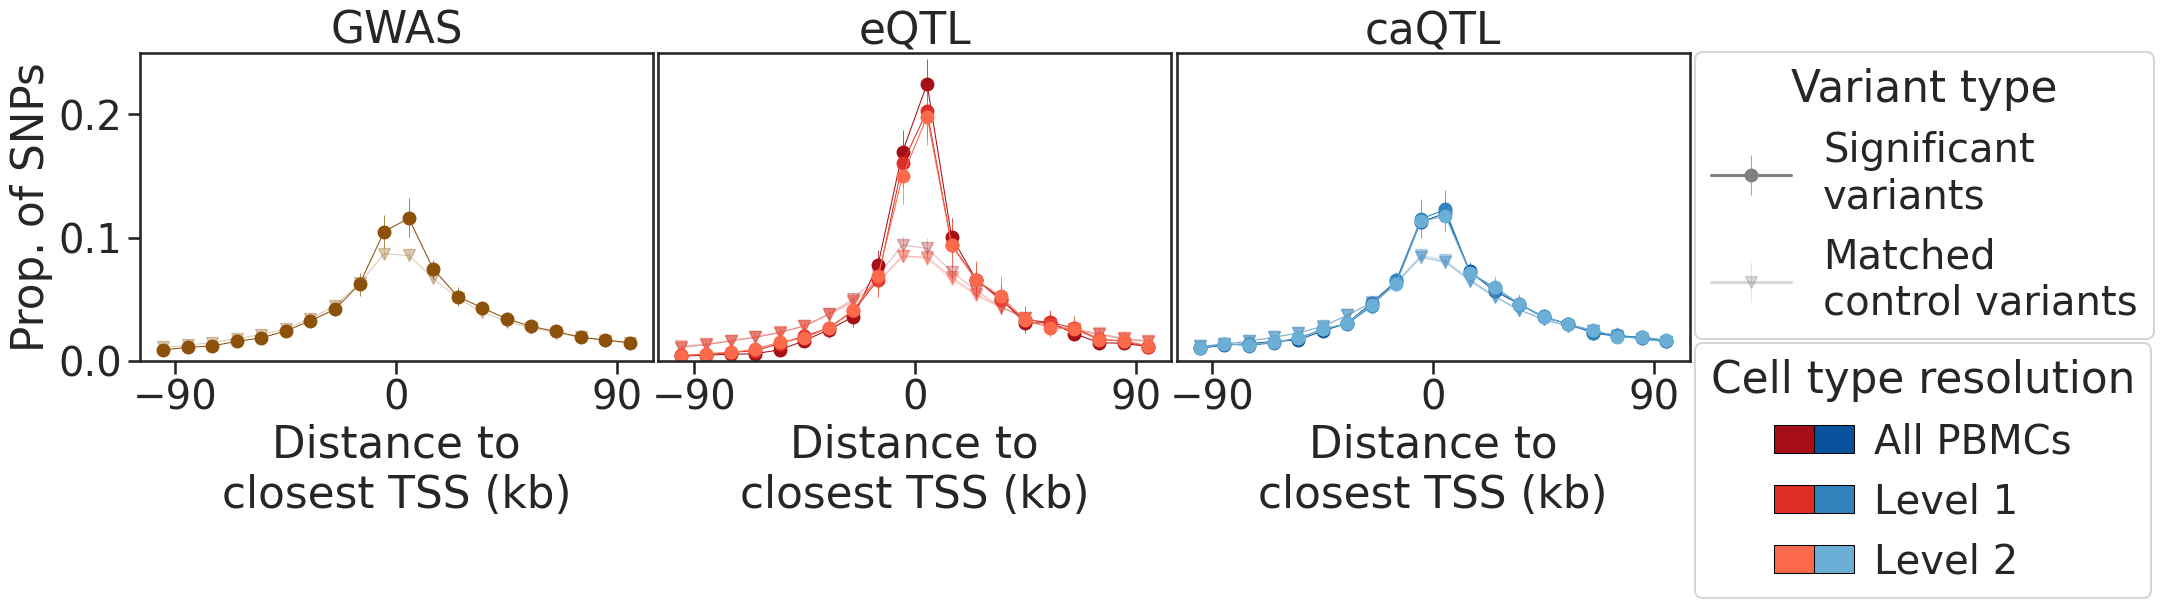

In [53]:
## OLD ##

sns.set_context('talk',font_scale=1.75)

fig, ax = plt.subplots(1, 3, figsize=(20, 4))
plt.subplots_adjust(wspace=0.01) 

# plot significant variants
plot_df = tss_results[tss_results["cat"] == "GWAS"]
ax[0].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, 
               marker="o", color=colors["GWAS"], label="GWAS")

# plot matched variants
plot_df = tss_results[tss_results["cat"] == "GWAS_matched"]
ax[0].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, marker="v", color=colors["GWAS"], alpha=0.3, label="GWAS matched")

# plot labels
ax[0].set_ylim(0, 0.25)
ax[0].set_xticks([-90, 0, 90])
ax[0].set_ylabel("Prop. of SNPs")
ax[0].set_xlabel("Distance to\nclosest TSS (kb)")
ax[0].set_title("GWAS")


for i, modality in enumerate(["eQTL", "caQTL"]):
    for j, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
        # plot significant variants
        plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                              (tss_results["Level"] == level) &
                              (tss_results["cat"] == "eQTL")]
        ax[i+1].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, 
               marker="o", color=colors[modality][level], label=level)
        
        # plot matched variants
        plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                              (tss_results["Level"] == level) &
                              (tss_results["cat"] == "eQTL_matched")]
        ax[i+1].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, marker="v", color=colors[modality][level], alpha=0.3)
        
        # plot labels
        ax[i+1].set_ylim(0, 0.25)
        ax[i+1].set_yticks([])
        ax[i+1].set_xticks([-90, 0, 90])
        ax[i+1].set_xlabel("Distance to\nclosest TSS (kb)")
        ax[i+1].set_title(modality)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
                  elinewidth=0.5, label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
                  elinewidth=0.5, label="Matched\ncontrol variants")
first_legend = ax[2].legend(handles=[l1, l2], loc=(1.01, 0.07), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax[2].add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.77), title="Cell type resolution")
plt.savefig(f"{data_dir}/figures/TSS_distance.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/TSS_distance.pdf", dpi=300, bbox_inches="tight")


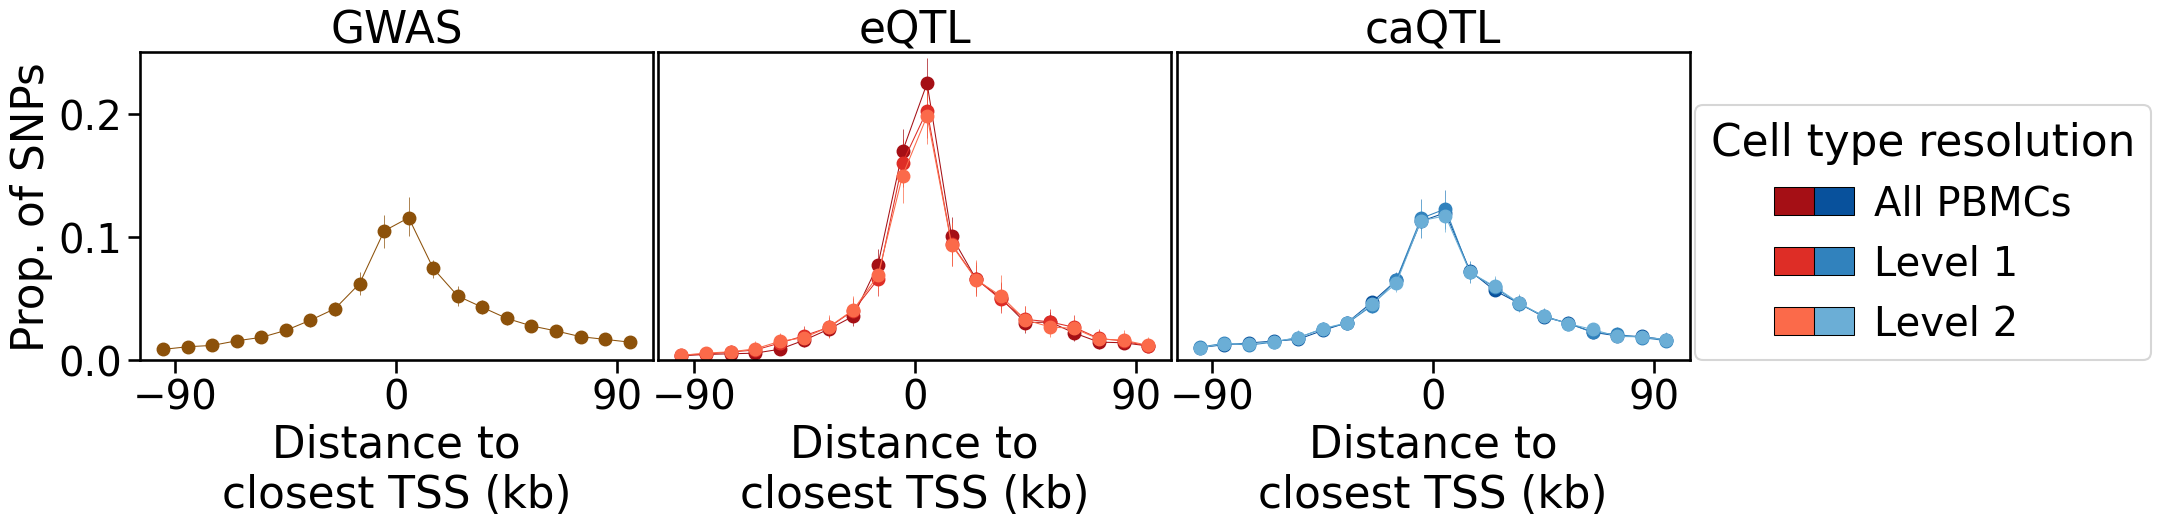

In [311]:
sns.set_context('talk',font_scale=1.75)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 3, figsize=(20, 4))
plt.subplots_adjust(wspace=0.01) 

# plot significant variants
plot_df = tss_results[tss_results["cat"] == "GWAS"]
ax[0].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, 
               marker="o", color=colors["GWAS"], label="GWAS")

# plot labels
ax[0].set_ylim(0, 0.25)
ax[0].set_xticks([-90, 0, 90])
ax[0].set_ylabel("Prop. of SNPs")
ax[0].set_xlabel("Distance to\nclosest TSS (kb)")
ax[0].set_title("GWAS")


for i, modality in enumerate(["eQTL", "caQTL"]):
    for j, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
        # plot significant variants
        plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                              (tss_results["Level"] == level) &
                              (tss_results["cat"] == "eQTL")]
        ax[i+1].errorbar(plot_df["dTSS_bin"], plot_df["mean"],
               np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
               linewidth=0.75, elinewidth=0.5, marker="o", color=colors[modality][level], label=level)
        
        # plot labels
        ax[i+1].set_ylim(0, 0.25)
        ax[i+1].set_yticks([])
        ax[i+1].set_xticks([-90, 0, 90])
        ax[i+1].set_xlabel("Distance to\nclosest TSS (kb)")
        ax[i+1].set_title(modality)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
plt.legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")
plt.savefig(f"{data_dir}/figures/TSS_distance_no_matched.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/TSS_distance_no_matched.pdf", dpi=300, bbox_inches="tight")


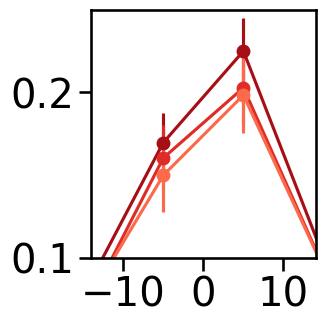

In [313]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))

modality = "eQTL"
for j, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
    plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                            (tss_results["Level"] == level) &
                            (tss_results["cat"] == "eQTL")]
    ax.errorbar(plot_df["dTSS_bin"], plot_df["mean"],
            np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
            marker="o", color=colors[modality][level], label=level)
    

ax.set_xlim(-14, 14)
ax.set_ylim(0.1, 0.25)
ax.set_yticks(np.arange(0.1, 0.21, 0.1))
plt.tight_layout()
plt.savefig(f"{data_dir}/figures/TSS_distance_inset_{modality}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/TSS_distance_inset_{modality}.pdf", dpi=300, bbox_inches="tight")

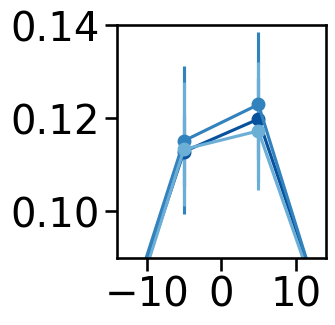

In [315]:
fig, ax = plt.subplots(1, 1, figsize=(4.1, 4))

modality = "caQTL"
for j, level in enumerate(["Cohort", "L1_manual", "L2_manual"]):
    plot_df = tss_results[(tss_results["Phenotype"] == modality) &
                            (tss_results["Level"] == level) &
                            (tss_results["cat"] == "eQTL")]
    ax.errorbar(plot_df["dTSS_bin"], plot_df["mean"],
            np.abs(plot_df[["lower", "upper"]].T.values - plot_df["mean"].values),
            marker="o", color=colors[modality][level], label=level)

ax.set_xlim(-14, 14)
ax.set_ylim(0.09, 0.14)
ax.set_yticks(np.arange(0.1, 0.15, 0.02))
plt.tight_layout()
plt.savefig(f"{data_dir}/figures/TSS_distance_inset_{modality}.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/TSS_distance_inset_{modality}.pdf", dpi=300, bbox_inches="tight")

## CRE plots

/tmp/ipykernel_1823/2597851040.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["x"] = np.array([
/tmp/ipykernel_1823/2597851040.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["color"] = [
/tmp/ipykernel_1823/2597851040.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

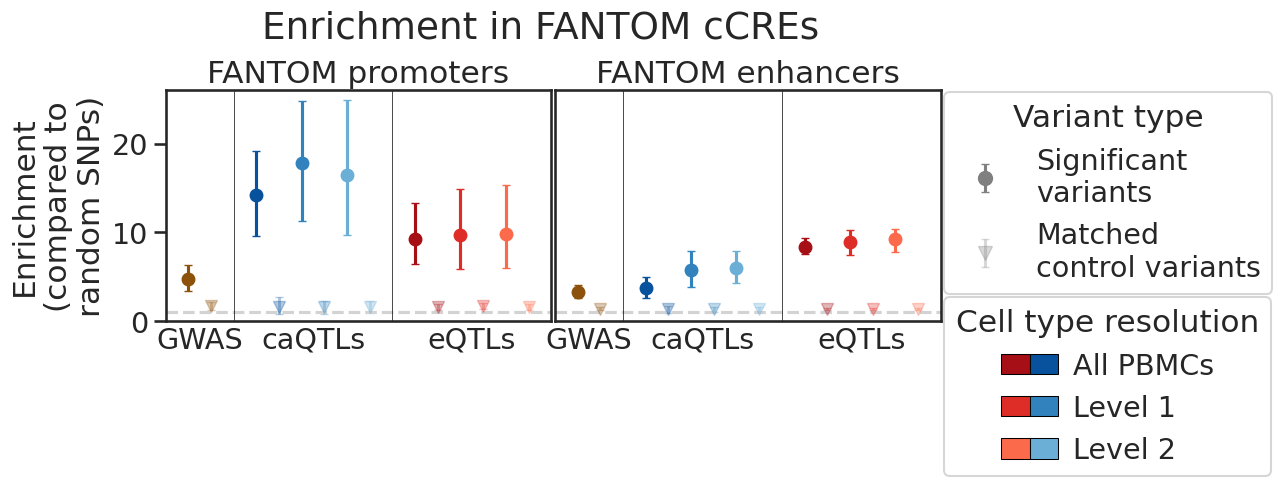

In [55]:
sns.set_context('talk', font_scale=1.25)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["FANTOM_promoter", "FANTOM_enhancer"]):
    plot_df = cre_results[cre_results["annot"].str.contains(annot)]
    
    # 1. Swapped x-coordinates to accommodate the order change
    plot_df["x"] = np.array([
        0, 0.05,                                # GWAS
        0.15, 0.2, 0.25, 0.3, 0.35, 0.4,        # caQTL (Moved here)
        0.5, 0.55, 0.6, 0.65, 0.7, 0.75         # eQTL (Moved here)
    ]) 
    
    # 2. Swapped color mapping logic
    plot_df["color"] = [
        colors["GWAS"], colors["GWAS"], 
        colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"],
        colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"]
    ]
    
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                capsize=3, linestyle="none")

    ax[j].set_xlim(-0.05, 0.8)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    
    # 3. Vertical lines and Ticks adjusted for the new order
    ax[j].vlines(0.1, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.45, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    # Updated labels to GWAS, caQTLs, eQTLs
    ax[j].set_xticks([0.025, 0.275, 0.625], ["GWAS", "caQTLs", "eQTLs"])
    ax[j].tick_params(axis='x', which='both', length=0)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])

ax[0].set_title("FANTOM promoters")
ax[1].set_title("FANTOM enhancers")
plt.suptitle("Enrichment in FANTOM cCREs", y=1.15)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched\ncontrol variants")
first_legend = ax[1].legend(handles=[l1, l2], loc=(1.01, 0.12), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax[1].add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[1].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.67), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment.pdf", dpi=300, bbox_inches="tight")

/tmp/ipykernel_11588/1638912897.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["x"] = np.array([0, 0.05,
/tmp/ipykernel_11588/1638912897.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["color"] = [colors["GWAS"], colors["GWAS"],
/tmp/ipykernel_11588/1638912897.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

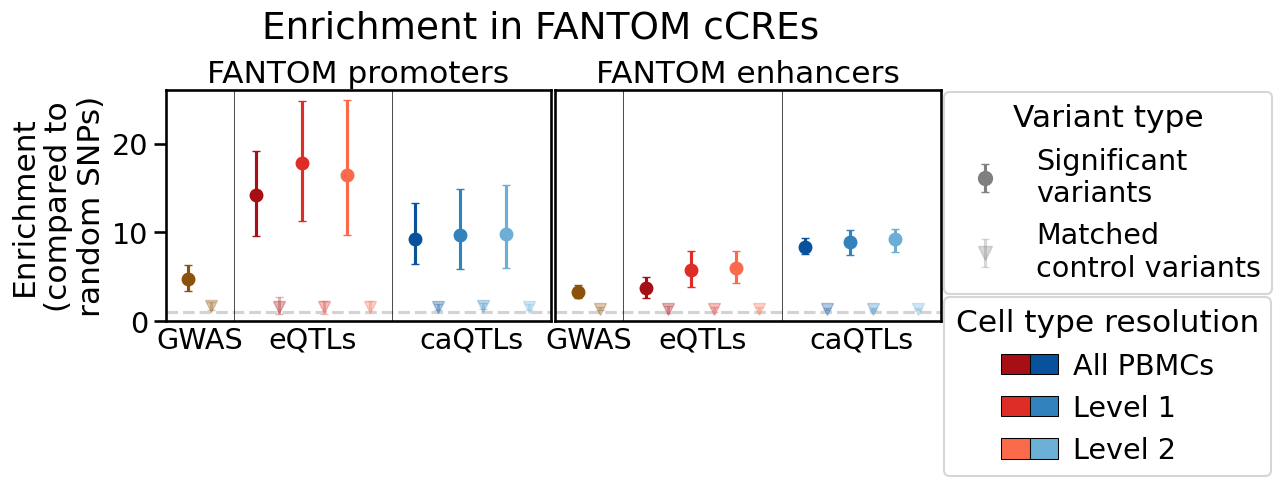

In [317]:
## OLD ##

sns.set_context('talk',font_scale=1.25)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 2,figsize=(10, 3))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["FANTOM_promoter", "FANTOM_enhancer"]):
    plot_df = cre_results[cre_results["annot"].str.contains(annot)]
    plot_df["x"] = np.array([0, 0.05, 
                    0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 
                    0.5, 0.55, 0.6, 0.65, 0.7, 0.75]) 
    plot_df["color"] = [colors["GWAS"], colors["GWAS"], 
                    colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"]]
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                label=label, capsize=3, linestyle="none")

    ax[j].set_xlim(-0.05, 0.8)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    ax[j].vlines(0.1, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.45, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    ax[j].set_xticks([0.025, 0.275, 0.625], ["GWAS", "eQTLs", "caQTLs"])
    ax[j].tick_params(axis='x', which='both',length=0)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])

ax[0].set_title("FANTOM promoters")
ax[1].set_title("FANTOM enhancers")
plt.suptitle("Enrichment in FANTOM cCREs", y=1.15)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched\ncontrol variants")
first_legend = ax[1].legend(handles=[l1, l2], loc=(1.01, 0.12), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax[1].add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[1].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.67), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment.pdf", dpi=300, bbox_inches="tight")

/tmp/ipykernel_11588/2353505075.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3
/tmp/ipykernel_11588/2353505075.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3


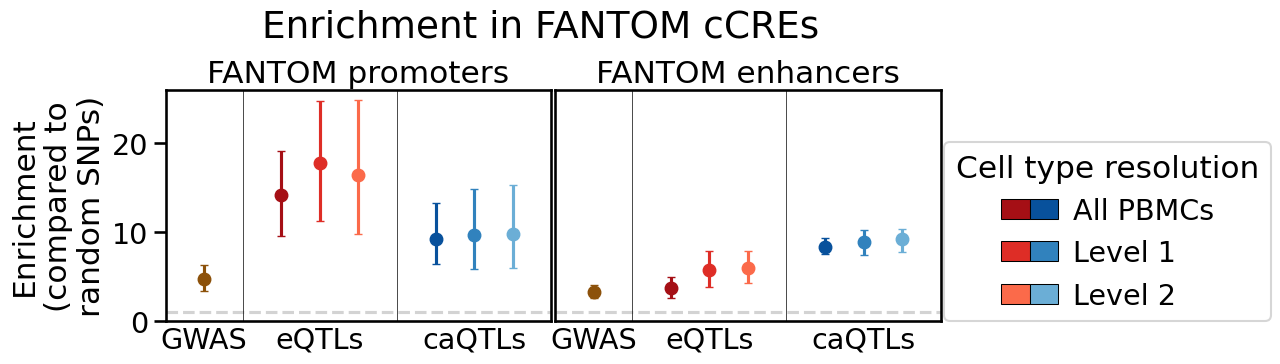

In [319]:
## OLD##

sns.set_context('talk',font_scale=1.25)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 2,figsize=(10, 3))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["FANTOM_promoter", "FANTOM_enhancer"]):
    plot_df = cre_results[cre_results["annot"].str.contains(annot)]
    plot_df = plot_df.loc[~plot_df["cat"].str.contains("matched")]
    plot_df["x"] = np.array([0, 
                    0.1, 0.15, 0.2,
                    0.3, 0.35, 0.4]) 
    plot_df["color"] = [colors["GWAS"],
                    colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"]]
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                label=label, capsize=3, linestyle="none")

    ax[j].set_xlim(-0.05, 0.45)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    ax[j].vlines(0.05, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.25, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    ax[j].set_xticks([0, 0.15, 0.35], ["GWAS", "eQTLs", "caQTLs"])
    ax[j].tick_params(axis='x', which='both',length=0)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])

ax[0].set_title("FANTOM promoters")
ax[1].set_title("FANTOM enhancers")
plt.suptitle("Enrichment in FANTOM cCREs", y=1.15)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[1].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment_no_matched.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/FANTOM_CRE_enrichment_no_matched.pdf", dpi=300, bbox_inches="tight")

/tmp/ipykernel_1823/1462273296.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3
/tmp/ipykernel_1823/1462273296.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3
/tmp/ipykernel_1823/1462273296.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3


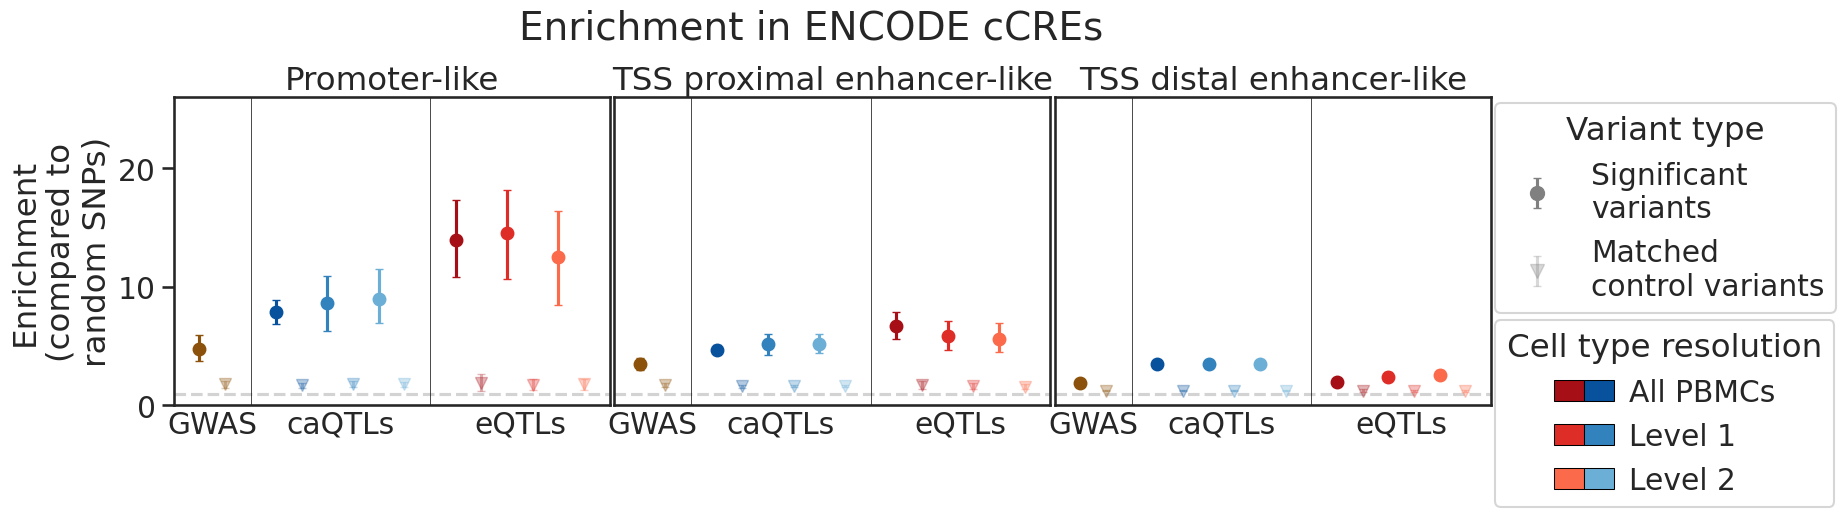

In [59]:
sns.set_context('talk', font_scale=1.3)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["ENCODE_PLS", "ENCODE_pELS", "ENCODE_dELS"]):
    # Filter for the annotation
    plot_df = cre_results[cre_results["annot"].str.contains(annot)].copy()
    
    # --- DATA SWAP LOGIC ---
    # Assuming your original DF order is: [GWAS(2), eQTL(6), caQTL(6)]
    # We create a new index to swap the blocks: [GWAS(0-1), caQTL(8-13), eQTL(2-7)]
    new_order = [0, 1, 8, 9, 10, 11, 12, 13, 2, 3, 4, 5, 6, 7]
    plot_df = plot_df.iloc[new_order].reset_index(drop=True)
    
    # 1. Update X-coordinates for the new order
    plot_df["x"] = np.array([0, 0.05,                         # GWAS
                             0.15, 0.2, 0.25, 0.3, 0.35, 0.4, # caQTL (New middle)
                             0.5, 0.55, 0.6, 0.65, 0.7, 0.75]) # eQTL (New end)
    
    # 2. Update Colors to match the swapped data
    plot_df["color"] = [
        colors["GWAS"], colors["GWAS"], 
        colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"],
        colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"]
    ]
    
    # Set markers and alpha
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                capsize=3, linestyle="none")

    # 3. Aesthetics
    ax[j].set_xlim(-0.05, 0.8)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    
    # Vertical separators (keep positions, but they now separate the new order)
    ax[j].vlines(0.1, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.45, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    # Updated Tick Labels
    ax[j].set_xticks([0.025, 0.275, 0.625], ["GWAS", "caQTLs", "eQTLs"])
    ax[j].tick_params(axis='x', which='both', length=0)

# ... [Rest of your formatting code remains the same] ...

# Labels and titles remain the same
ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])
ax[2].set_yticks([])

ax[0].set_title("Promoter-like")
ax[1].set_title("TSS proximal enhancer-like")
ax[2].set_title("TSS distal enhancer-like")
plt.suptitle("Enrichment in ENCODE cCREs", y=1.1)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])
ax[2].set_yticks([])

ax[0].set_title("Promoter-like")
ax[1].set_title("TSS proximal enhancer-like")
ax[2].set_title("TSS distal enhancer-like")
plt.suptitle("Enrichment in ENCODE cCREs", y=1.1)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched\ncontrol variants")
first_legend = ax[2].legend(handles=[l1, l2], loc=(1.01, 0.3), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax[2].add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[2].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.33), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment.pdf", dpi=300, bbox_inches="tight")

/tmp/ipykernel_11588/3068202345.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["x"] = np.array([0, 0.05,
/tmp/ipykernel_11588/3068202345.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["color"] = [colors["GWAS"], colors["GWAS"],
/tmp/ipykernel_11588/3068202345.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

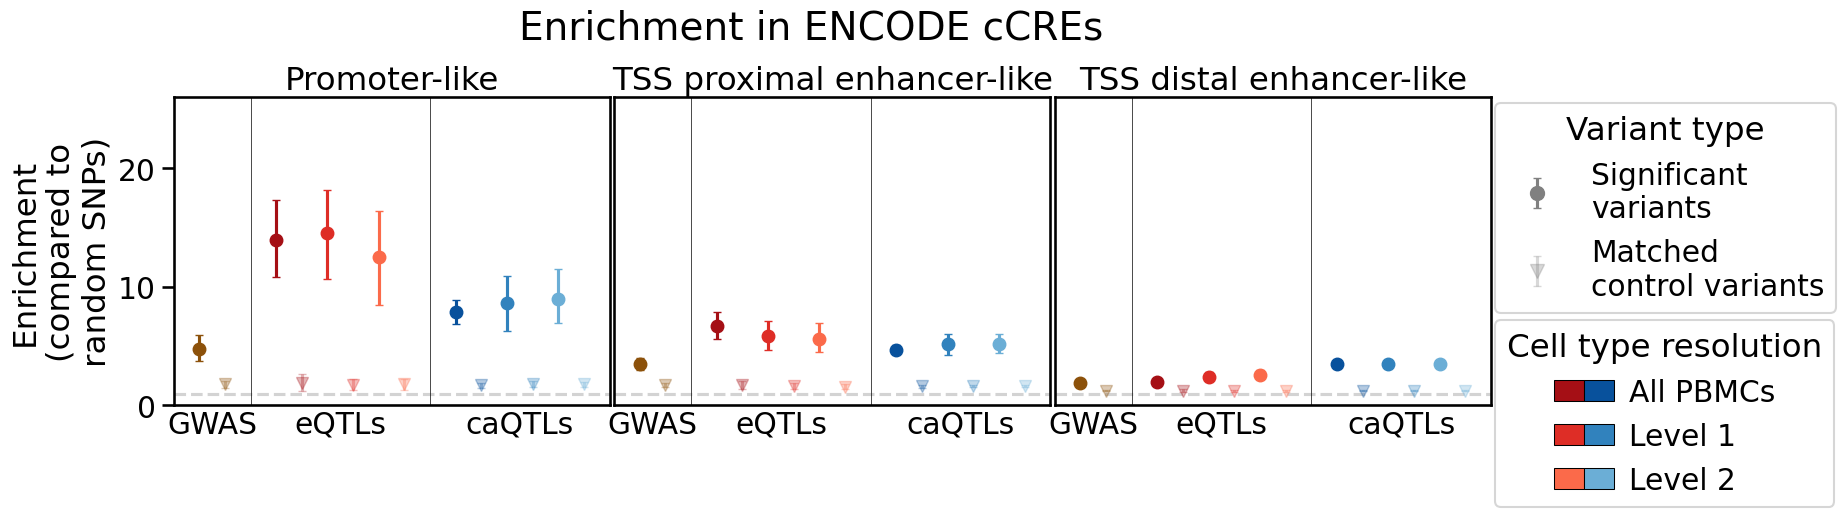

In [321]:
## OLD ##
sns.set_context('talk',font_scale=1.3)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 3,figsize=(17, 4))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["ENCODE_PLS", "ENCODE_pELS", "ENCODE_dELS"]):
    plot_df = cre_results[cre_results["annot"].str.contains(annot)]
    plot_df["x"] = np.array([0, 0.05, 
                    0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 
                    0.5, 0.55, 0.6, 0.65, 0.7, 0.75]) 
    plot_df["color"] = [colors["GWAS"], colors["GWAS"], 
                    colors["eQTL"]["Cohort"], colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"], colors["caQTL"]["L2_manual"]]
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                label=label, capsize=3, linestyle="none")

    ax[j].set_xlim(-0.05, 0.8)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    ax[j].vlines(0.1, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.45, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    ax[j].set_xticks([0.025, 0.275, 0.625], ["GWAS", "eQTLs", "caQTLs"])
    ax[j].tick_params(axis='x', which='both',length=0)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])
ax[2].set_yticks([])

ax[0].set_title("Promoter-like")
ax[1].set_title("TSS proximal enhancer-like")
ax[2].set_title("TSS distal enhancer-like")
plt.suptitle("Enrichment in ENCODE cCREs", y=1.1)

# Create the first legend
l1 = plt.errorbar(-1, -1, yerr=0, marker="o", alpha=1, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Significant\nvariants")
l2 = plt.errorbar(-1, -1, yerr=0, marker="v", alpha=0.3, color="gray",
            markersize=10, capsize=3, linestyle="none", label="Matched\ncontrol variants")
first_legend = ax[2].legend(handles=[l1, l2], loc=(1.01, 0.3), 
                         title='Variant type')
# Add the first legend manually to the Axes
ax[2].add_artist(first_legend)

# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[2].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, -0.33), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment.pdf", dpi=300, bbox_inches="tight")

/tmp/ipykernel_11588/3229011851.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3
/tmp/ipykernel_11588/3229011851.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3
/tmp/ipykernel_11588/3229011851.py:19: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.3' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3


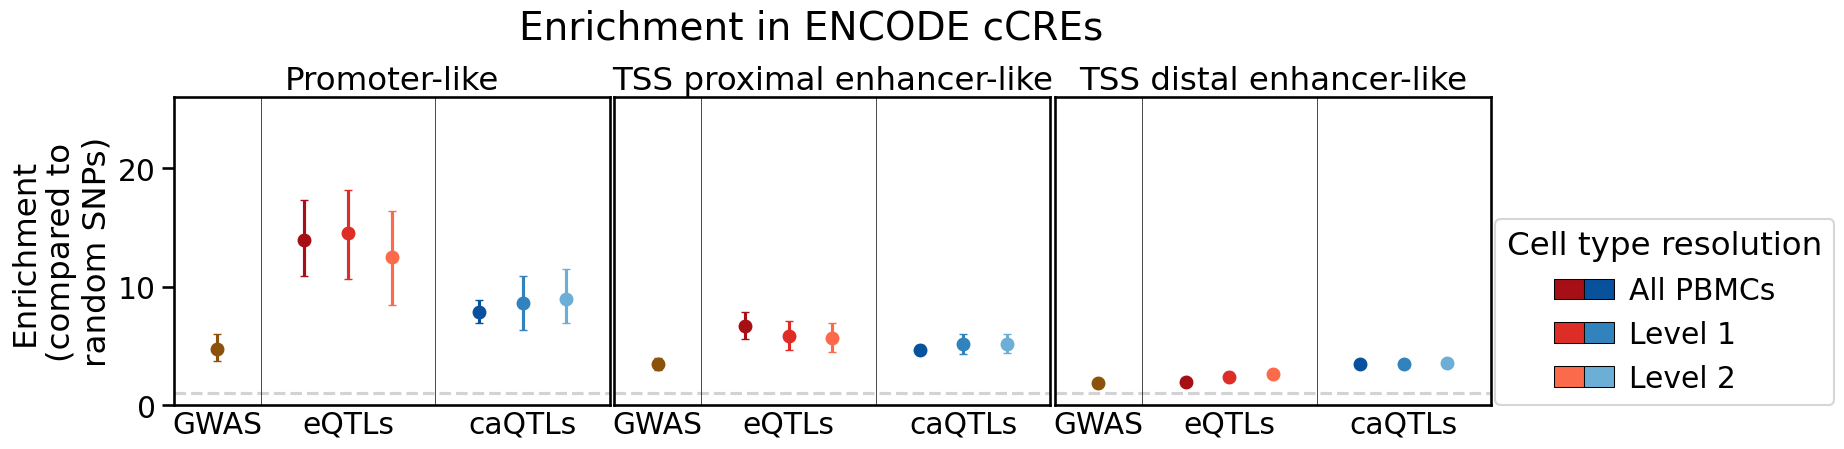

In [323]:
sns.set_context('talk',font_scale=1.3)

cmap = plt.get_cmap("tab20c")
fig, ax = plt.subplots(1, 3,figsize=(17, 4))
plt.subplots_adjust(wspace=0.01) 

for j, annot in enumerate(["ENCODE_PLS", "ENCODE_pELS", "ENCODE_dELS"]):
    plot_df = cre_results[cre_results["annot"].str.contains(annot)]
    plot_df = plot_df.loc[~plot_df["cat"].str.contains("matched")]
    plot_df["x"] = np.array([0,
                    0.1, 0.15, 0.2, 
                    0.3, 0.35, 0.4]) 
    plot_df["color"] = [colors["GWAS"],
                    colors["eQTL"]["Cohort"], colors["eQTL"]["L1_manual"], colors["eQTL"]["L2_manual"],
                    colors["caQTL"]["Cohort"], colors["caQTL"]["L1_manual"], colors["caQTL"]["L2_manual"]]
    plot_df["marker"] = "o"
    plot_df["alpha"] = 1
    plot_df.loc[plot_df["cat"].str.contains("matched"), "marker"] = "v"
    plot_df.loc[plot_df["cat"].str.contains("matched"), "alpha"] = 0.3

    for i, row in plot_df.iterrows():
        ax[j].errorbar(row["x"], row["mean"],
                yerr=np.abs(row[["lower", "upper"]].T.values - row["mean"]).reshape(-1, 1),
                 marker=row["marker"], 
                alpha=row["alpha"], color=row["color"],
                label=label, capsize=3, linestyle="none")

    ax[j].set_xlim(-0.05, 0.45)   
    ax[j].set_ylim(0, 26)
    ax[j].hlines(1, ax[j].get_xlim()[0], ax[j].get_xlim()[1], linestyle="--", color="lightgray")
    ax[j].vlines(0.05, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)
    ax[j].vlines(0.25, ax[j].get_ylim()[0], ax[j].get_ylim()[1], color="black", linewidth=0.5)

    ax[j].set_xticks([0, 0.15, 0.35], ["GWAS", "eQTLs", "caQTLs"])
    ax[j].tick_params(axis='x', which='both',length=0)

ax[0].set_ylabel("Enrichment\n(compared to\nrandom SNPs)")
ax[1].set_yticks([])
ax[2].set_yticks([])

ax[0].set_title("Promoter-like")
ax[1].set_title("TSS proximal enhancer-like")
ax[2].set_title("TSS distal enhancer-like")
plt.suptitle("Enrichment in ENCODE cCREs", y=1.1)


# second legend
pa1 = Patch(facecolor=colors["eQTL"]["Cohort"], edgecolor='black', linewidth=0.75)
pa2 = Patch(facecolor=colors["caQTL"]["Cohort"], edgecolor='black', linewidth=0.75)

pb1 = Patch(facecolor=colors["eQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)
pb2 = Patch(facecolor=colors["caQTL"]["L1_manual"], edgecolor='black', linewidth=0.75)

pc1 = Patch(facecolor=colors["eQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
pc2 = Patch(facecolor=colors["caQTL"]["L2_manual"], edgecolor='black', linewidth=0.75)
ax[2].legend(handles=[pa1, pb1, pc1, pa2, pb2, pc2],
          labels=['', '', '', 'All PBMCs','Level 1',  'Level 2'],
          ncol=2, handletextpad=0.5, handlelength=1.0, columnspacing=-0.5,
          loc=(1.01, 0), title="Cell type resolution")

plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment_no_matched.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{data_dir}/figures/ENCODE_CRE_enrichment_no_matched.pdf", dpi=300, bbox_inches="tight")